In [1]:
import sys
sys.path.append("..")  # lets the notebook import from src/

from pathlib import Path

import matplotlib.pyplot as plt

from src.data import load_data

#load dataset
df = load_data("../data/raw/hour.csv")
#create folder for graphs
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

#displays statistics and transpose output 
df.describe().T

,count,mean,min,25%,50%,75%,max,std
season,17379.0,2.50164,1.0,2.0,3.0,3.0,4.0,1.106918
month,17379.0,6.537775,1.0,4.0,7.0,10.0,12.0,3.438776
hour,17379.0,11.546752,0.0,6.0,12.0,18.0,23.0,6.914405
holiday,17379.0,0.02877,0.0,0.0,0.0,0.0,1.0,0.167165
weekday,17379.0,3.003683,0.0,1.0,3.0,5.0,6.0,2.005771
workingday,17379.0,0.682721,0.0,0.0,1.0,1.0,1.0,0.465431
weather,17379.0,1.425283,1.0,1.0,1.0,2.0,4.0,0.639357
temp,17379.0,0.496987,0.02,0.34,0.5,0.66,1.0,0.192556
atemp,17379.0,0.475775,0.0,0.3333,0.4848,0.6212,1.0,0.17185
humidity,17379.0,0.627229,0.0,0.48,0.63,0.78,1.0,0.19293


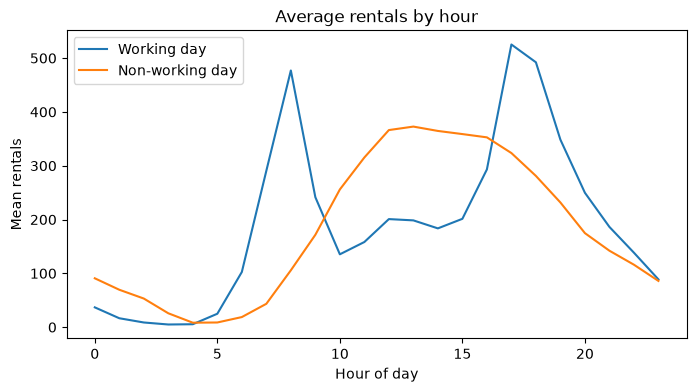

In [2]:
#create graph 
fig, ax = plt.subplots(figsize=(8, 4))
#loops through working days and non working days
#working day - flag becomes one , non working day - flag becomes 0
for flag, label in [(1, "Working day"), (0, "Non-working day")]:
    # calculate average rentals and plot them 
    #selects rows matching current time of day, groups rows by hr, selects number of bikes rented
    #calculates mean then plots results and adds graph title & axis label
    df[df["workingday"] == flag].groupby("hour")["count"].mean().plot(ax=ax, label=label)
ax.set(title="Average rentals by hour", xlabel="Hour of day", ylabel="Mean rentals")
#adds legend - identifying which line is working day and which is non working day
ax.legend()
#saves graph
fig.savefig(FIG_DIR / "demand_by_hour.png", dpi=150, bbox_inches="tight")

On working days, rentals peak around 8am and 5-6pm which suggests commuters. On weekends, there is a broad peak around midday so 'hour' and 'workingday' is important features for the model.

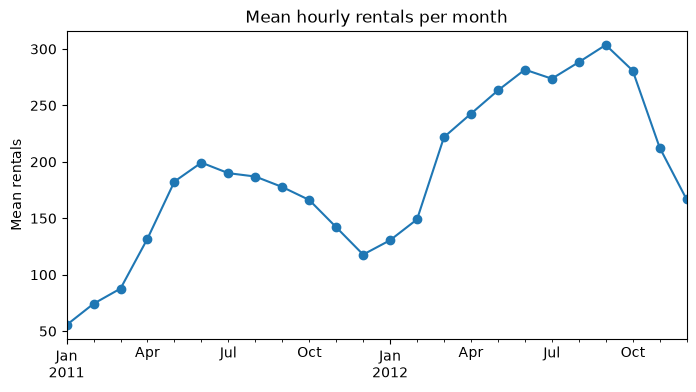

In [3]:
#sets datetime as the index, selects rental counts, group records by month
#calculates mean for each month
monthly = df.set_index("datetime")["count"].resample("MS").mean()
# creates graph
fig, ax = plt.subplots(figsize=(8, 4))
# plot monthly averages 
monthly.plot(ax=ax, marker="o")
#adds title and axis labels
ax.set(title="Mean hourly rentals per month", xlabel="", ylabel="Mean rentals")
#saves graph
fig.savefig(FIG_DIR / "demand_over_time.png", dpi=150, bbox_inches="tight")

In 2012 there seems to be a higher demand for bike rentals than 2011, so there is an upwards trend. This is why I will split the train and test data by time as the model will face higher demand than it saw in training.

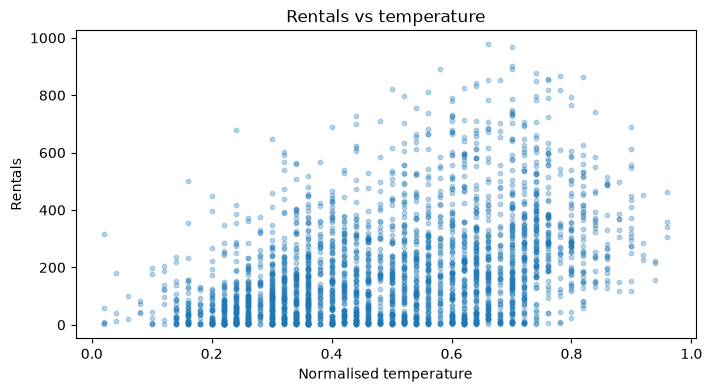

In [4]:
#takes 3000 rows from dataset and stores in sample, makes random selection reproducible
sample = df.sample(3000, random_state=42)
#creates graph
fig, ax = plt.subplots(figsize=(8, 4))
#creates a scatter graph of temp and count of bike rentals, added title and axis label
ax.scatter(sample["temp"], sample["count"], alpha=0.3, s=10)
ax.set(title="Rentals vs temperature", xlabel="Normalised temperature", ylabel="Rentals")
#saves graph
fig.savefig(FIG_DIR / "demand_vs_temp.png", dpi=150, bbox_inches="tight")

The rentals increase as the temperatures get warmer, however there is a lot of spread, so temperatures isn't the only factor that affects bike rentals.

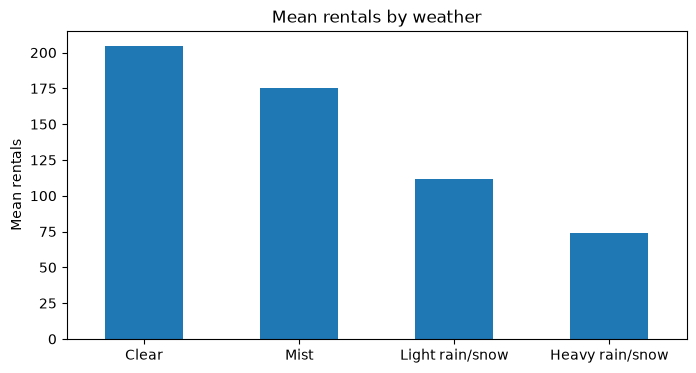

In [5]:
#replaces the weather codes with labels
labels = {1: "Clear", 2: "Mist", 3: "Light rain/snow", 4: "Heavy rain/snow"}
#groups rows by weather code, selects rental count
# calaculates averge rentals for each weather condition and renames code into labels
by_weather = df.groupby("weather")["count"].mean().rename(index=labels)
#creates graph and bar chart
fig, ax = plt.subplots(figsize=(8, 4))
by_weather.plot.bar(ax=ax, rot=0)
#adds title and labels
ax.set(title="Mean rentals by weather", xlabel="", ylabel="Mean rentals")
# saves bar hart
fig.savefig(FIG_DIR / "demand_by_weather.png", dpi=150, bbox_inches="tight")

The average number of rentals decreases as weather gets worse.